# Classical CV, GCV, AICc and BIC

Cortés-Toto, Guerrero & Reyes (2017) compare these *in-sample* selection rules. Their numerical scales differ, so compare the selected $\lambda$ or normalized smoothness rather than raw criterion magnitudes.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## Create published-style data

We generate a deterministic nonlinear trend plus Gaussian noise; we do not use future observations or the experimental forecasting TSCV objective.

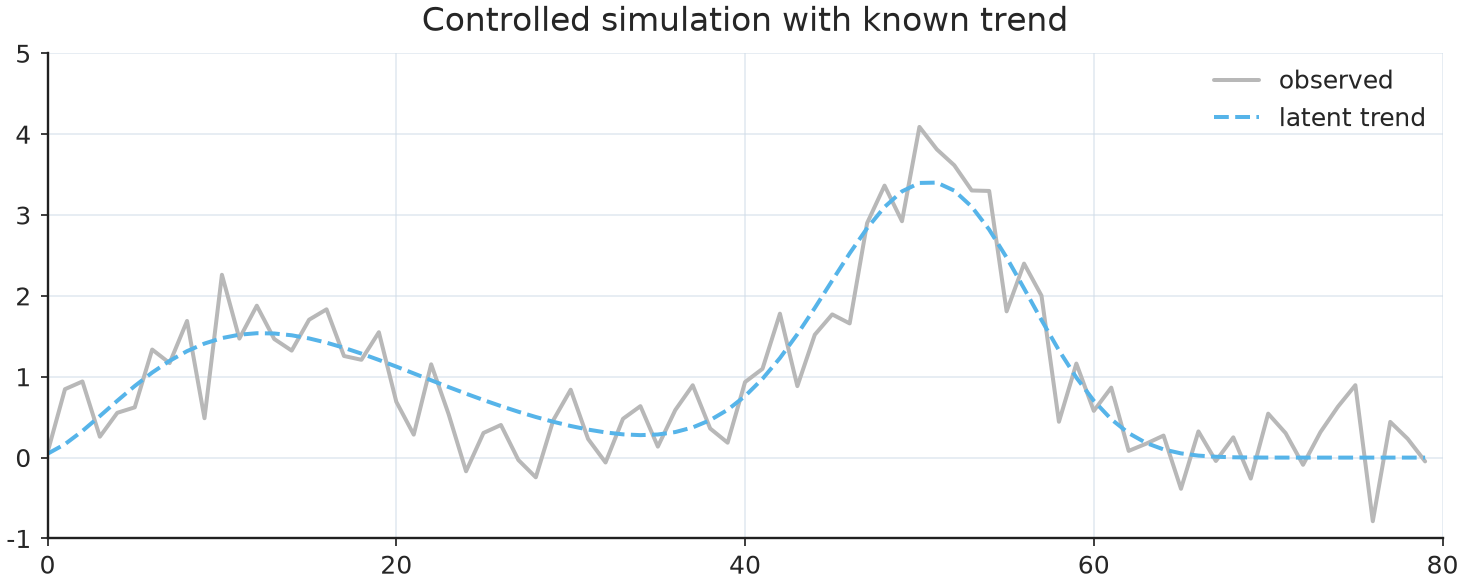

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from trendestimation import TrendSmoother,simulate_cortes_toto,select_lambda
data=simulate_cortes_toto(n=80,shape="nonlinear",noise_sd=.5,seed=11)
y=data.observed
fig,ax=plt.subplots(figsize=(10,3.5))
ax.plot(y,color="0.72",label="observed");ax.plot(data.trend,label="latent trend")
ax.legend();ax.set(title="Controlled simulation with known trend");plt.show()

## Fit every criterion

For fixed $\mu=0$, classical leverage-based CV, trace-based GCV, corrected AIC and BIC can be evaluated using the reused spectral decomposition.

CV   : λ=25.0709, normalized S=0.847, score=0.2109
GCV  : λ=24.6641, normalized S=0.847, score=0.2126
AICC : λ=31.0503, normalized S=0.856, score=-1.484
BIC  : λ=2.46641e-07, normalized S=0.000, score=-23.45


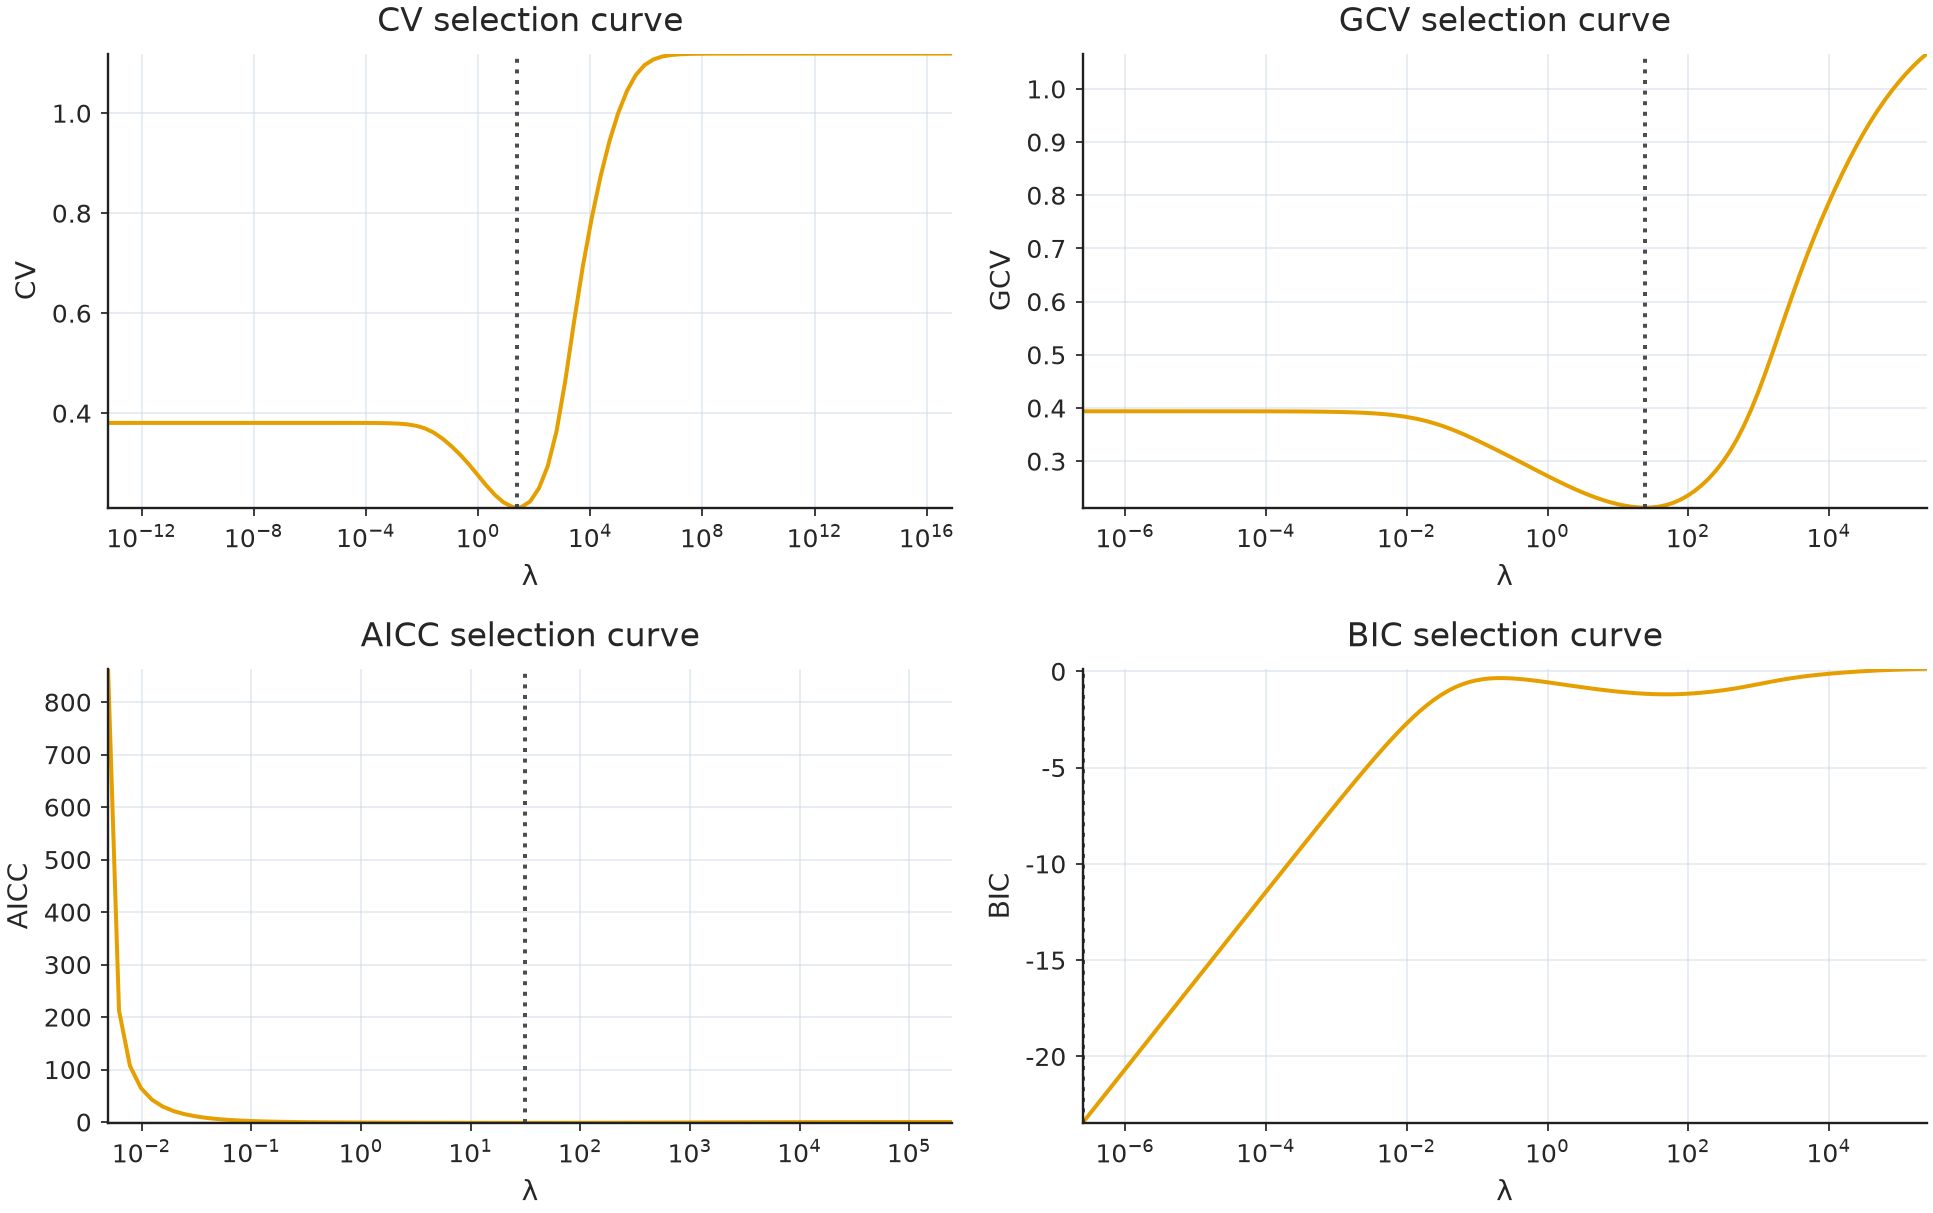

In [3]:
sm=TrendSmoother(len(y),order=2)
names=["cv","gcv","aicc","bic"]
results={name:select_lambda(sm,y,criterion=name,mu=0.0) for name in names}
for name,r in results.items():
    print(f"{name.upper():5s}: λ={r.lambda_:.6g}, normalized S={r.smoothness:.3f}, score={r.score:.4g}")
fig,axs=plt.subplots(2,2,figsize=(11,7))
for ax,(name,r) in zip(axs.flat,results.items()):
    ok=np.isfinite(r.grid)&np.isfinite(r.scores)&(r.grid>0)
    ax.semilogx(r.grid[ok],r.scores[ok])
    if np.isfinite(r.lambda_):ax.axvline(r.lambda_,color="0.3",ls=":")
    ax.set(xlabel="λ",ylabel=name.upper(),title=f"{name.upper()} selection curve")
fig.tight_layout();plt.show()

## Recovered trends and diagnostic loss

The known synthetic truth provides descriptive *latent-trend recovery error*, not out-of-sample predictive accuracy.

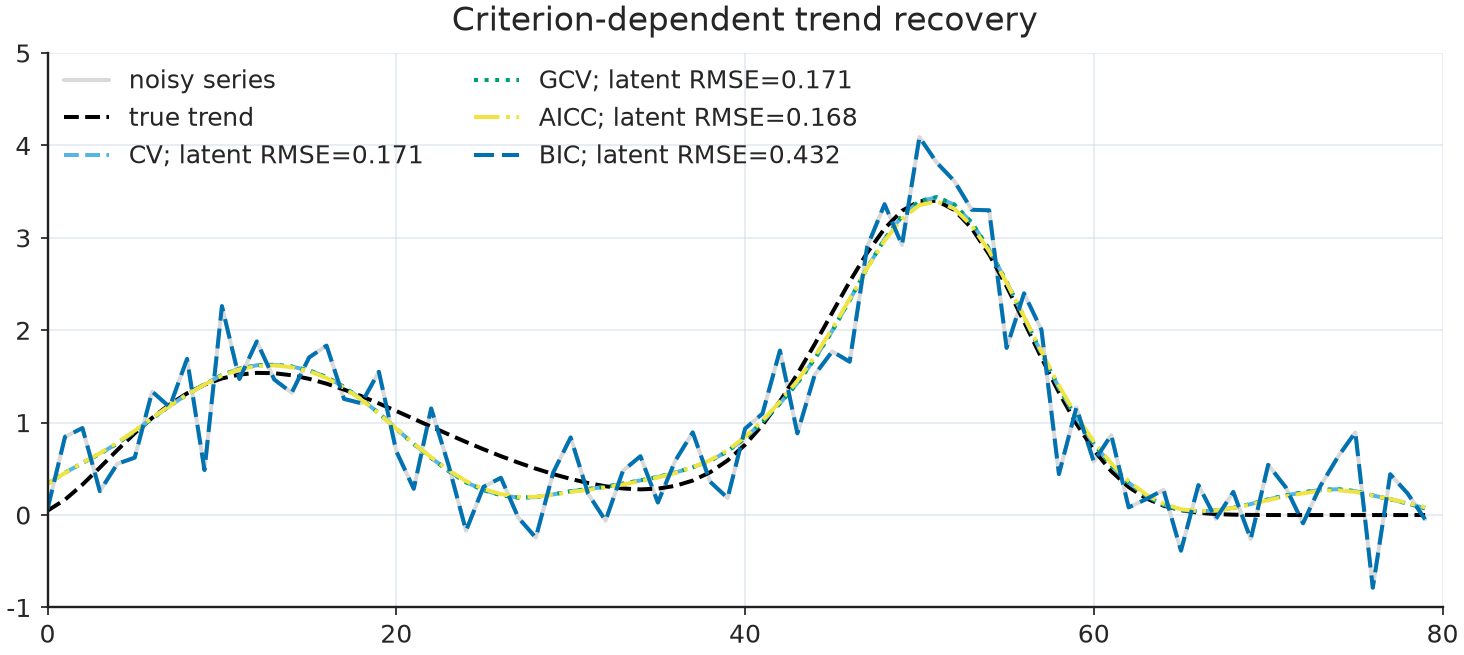

In [4]:
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(y,color="0.85",label="noisy series")
ax.plot(data.trend,"k--",label="true trend")
for name,r in results.items():
    fit=sm.fit(y,lambda_=r.lambda_)
    rmse=np.sqrt(np.mean((fit.trend-data.trend)**2))
    ax.plot(fit.trend,label=f"{name.upper()}; latent RMSE={rmse:.3f}")
ax.legend(ncol=2);ax.set(title="Criterion-dependent trend recovery");plt.show()

## Gaussian MLE and its two variance components

The four selectors above are the **classical in-sample criteria**. A separate Gaussian marginal maximum-likelihood selector, `criterion="mle"`, assumes independent observation noise and a Gaussian penalty for the latent second differences. It estimates a smoothing penalty from the profile likelihood, then reports an **observation-noise variance** and a **latent difference variance**. These are **not** the residual MSE or a forecast error variance. In this example `mu=0.0` is fixed.

Gaussian MLE: lambda=15.562
Observation-noise variance: 0.16989
Latent second-difference variance: 0.010917
Observation SD: 0.41217
Latent difference SD: 0.10448


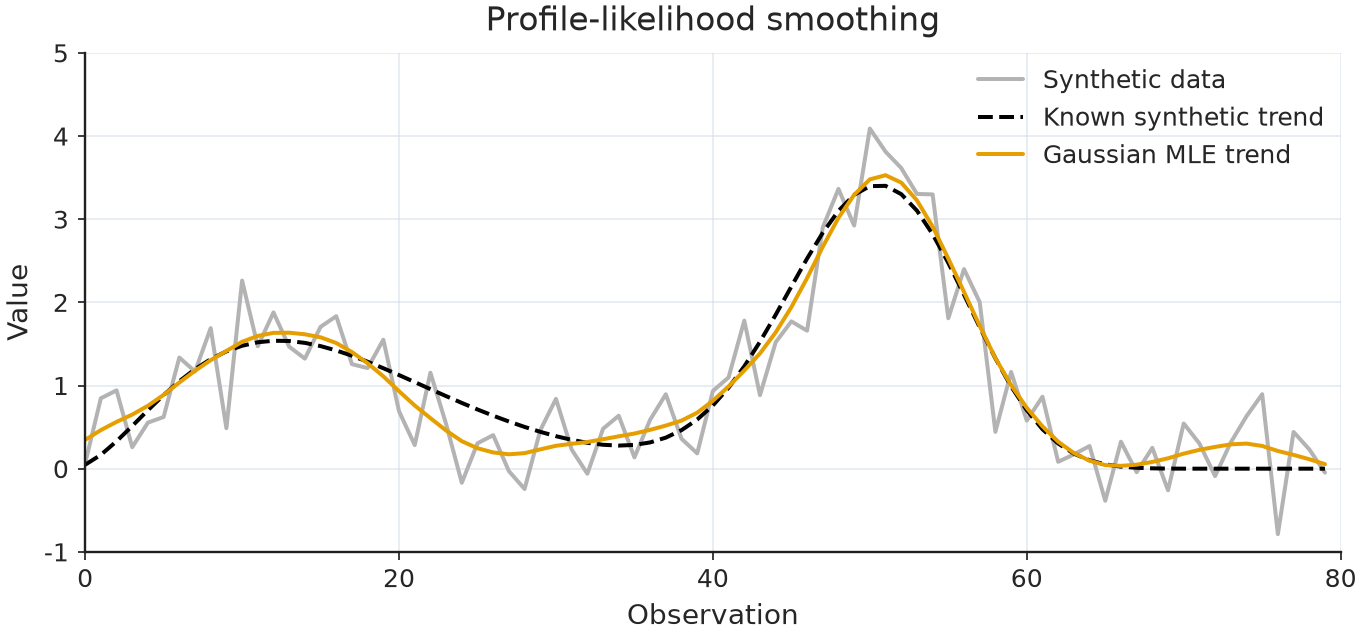

In [5]:
from trendestimation import estimate_variance_components

mle = select_lambda(sm, y, criterion="mle", mu=0.0)
components = estimate_variance_components(
    sm, y, lambda_=mle.lambda_, mu=0.0
)
print(f"Gaussian MLE: lambda={mle.lambda_:.5g}")
print(f"Observation-noise variance: {components.observation_variance:.5g}")
print(f"Latent second-difference variance: {components.difference_variance:.5g}")
print(f"Observation SD: {components.observation_sd:.5g}")
print(f"Latent difference SD: {components.difference_sd:.5g}")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(y, "-", color="0.7", label="Synthetic data")
ax.plot(data.trend, "k--", label="Known synthetic trend")
ax.plot(sm.fit(y, lambda_=mle.lambda_, mu=0.0).trend, label="Gaussian MLE trend")
ax.set(xlabel="Observation", ylabel="Value", title="Profile-likelihood smoothing")
ax.legend()
plt.show()

## Matched penalty and smoothness score plots

For the current notebook data (or a labeled synthetic fallback), compare CV, GCV, AICc and BIC versus $\lambda$ **and** $S(\lambda)$; the mapped grids have identical candidate penalties. Each execution saves inline SVG and PNG figures. The single GCV selector timing is illustrative and is **not** a controlled speed comparison; use the separate multi-seed benchmark for that.

Paired coordinates: last 60 observations of the notebook series; n=60, d=2, mu=0
Normalized S grid: [0.       0.1      0.2      0.3      0.4      0.5      0.6      0.7
 0.8      0.9      0.95     0.99     0.999    0.9999   0.999999 1.      ]
S=0 maps to lambda=0; S=1 maps to lambda=+infinity.
Near-1 targets: S=0.950000 -> lambda=886.169, S=0.990000 -> lambda=33003.8, S=0.999000 -> lambda=510198, S=0.999900 -> lambda=5.29957e+06, S=0.999999 -> lambda=5.32145e+08
Maximum inversion / round-trip error: 1.33e-15


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


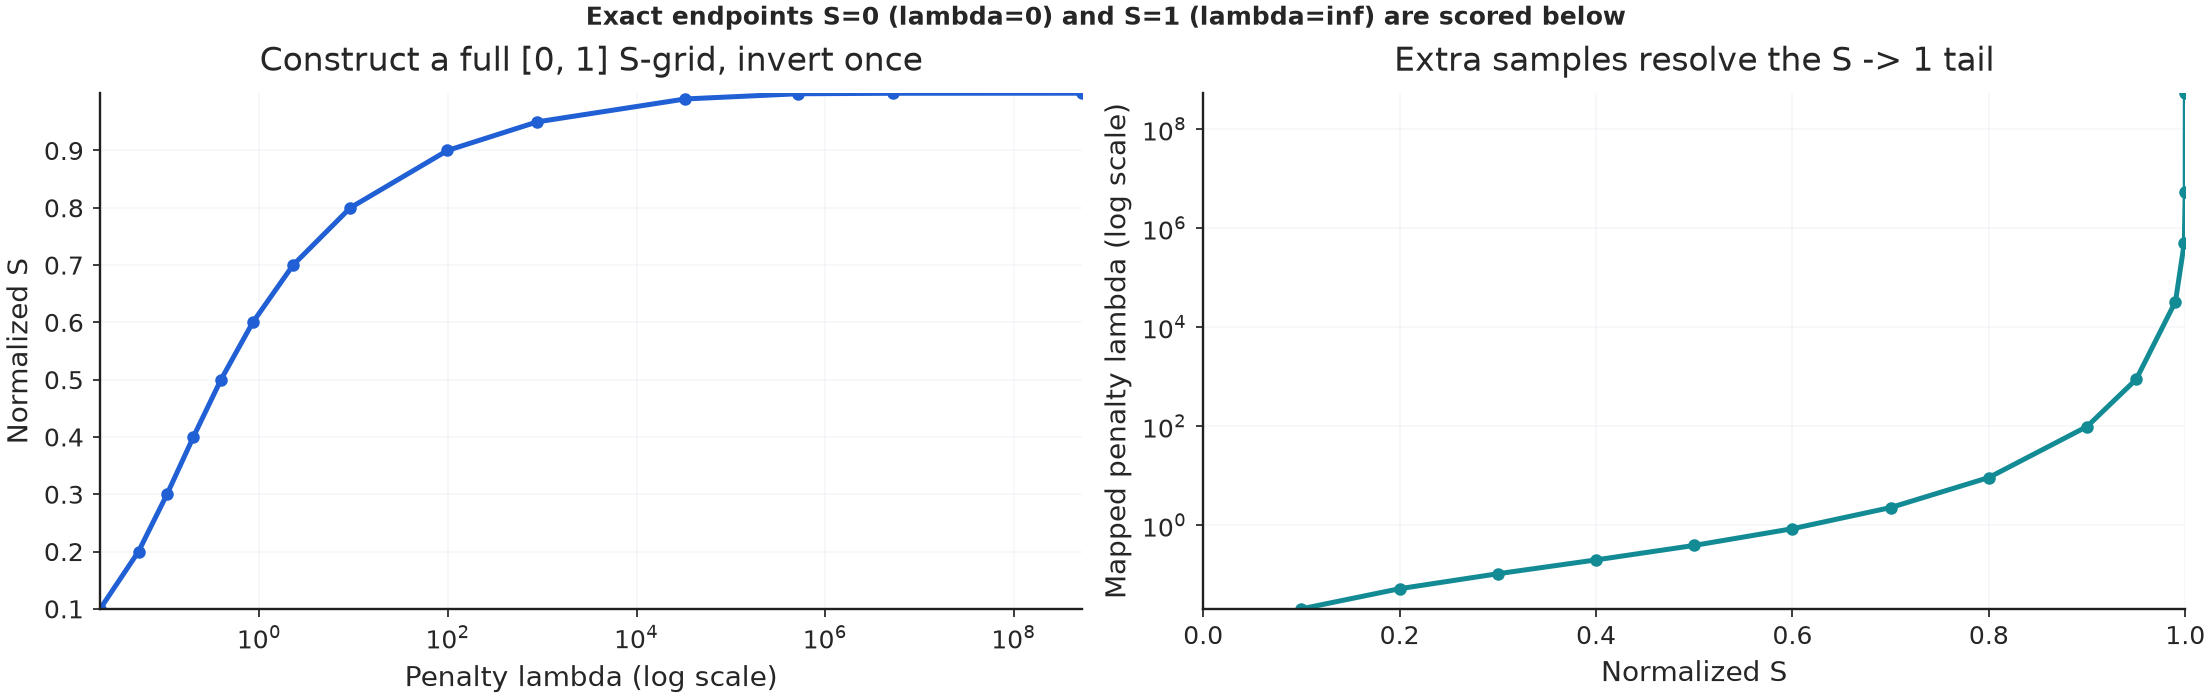

  CV: lambda=    9.21334, S=0.8, score=0.212028
 GCV: lambda=    9.21334, S=0.8, score=0.217924
AICC: lambda=    9.21334, S=0.8, score=-1.40257
 BIC: lambda=  0.0205109, S=0.1, score=-2.0255


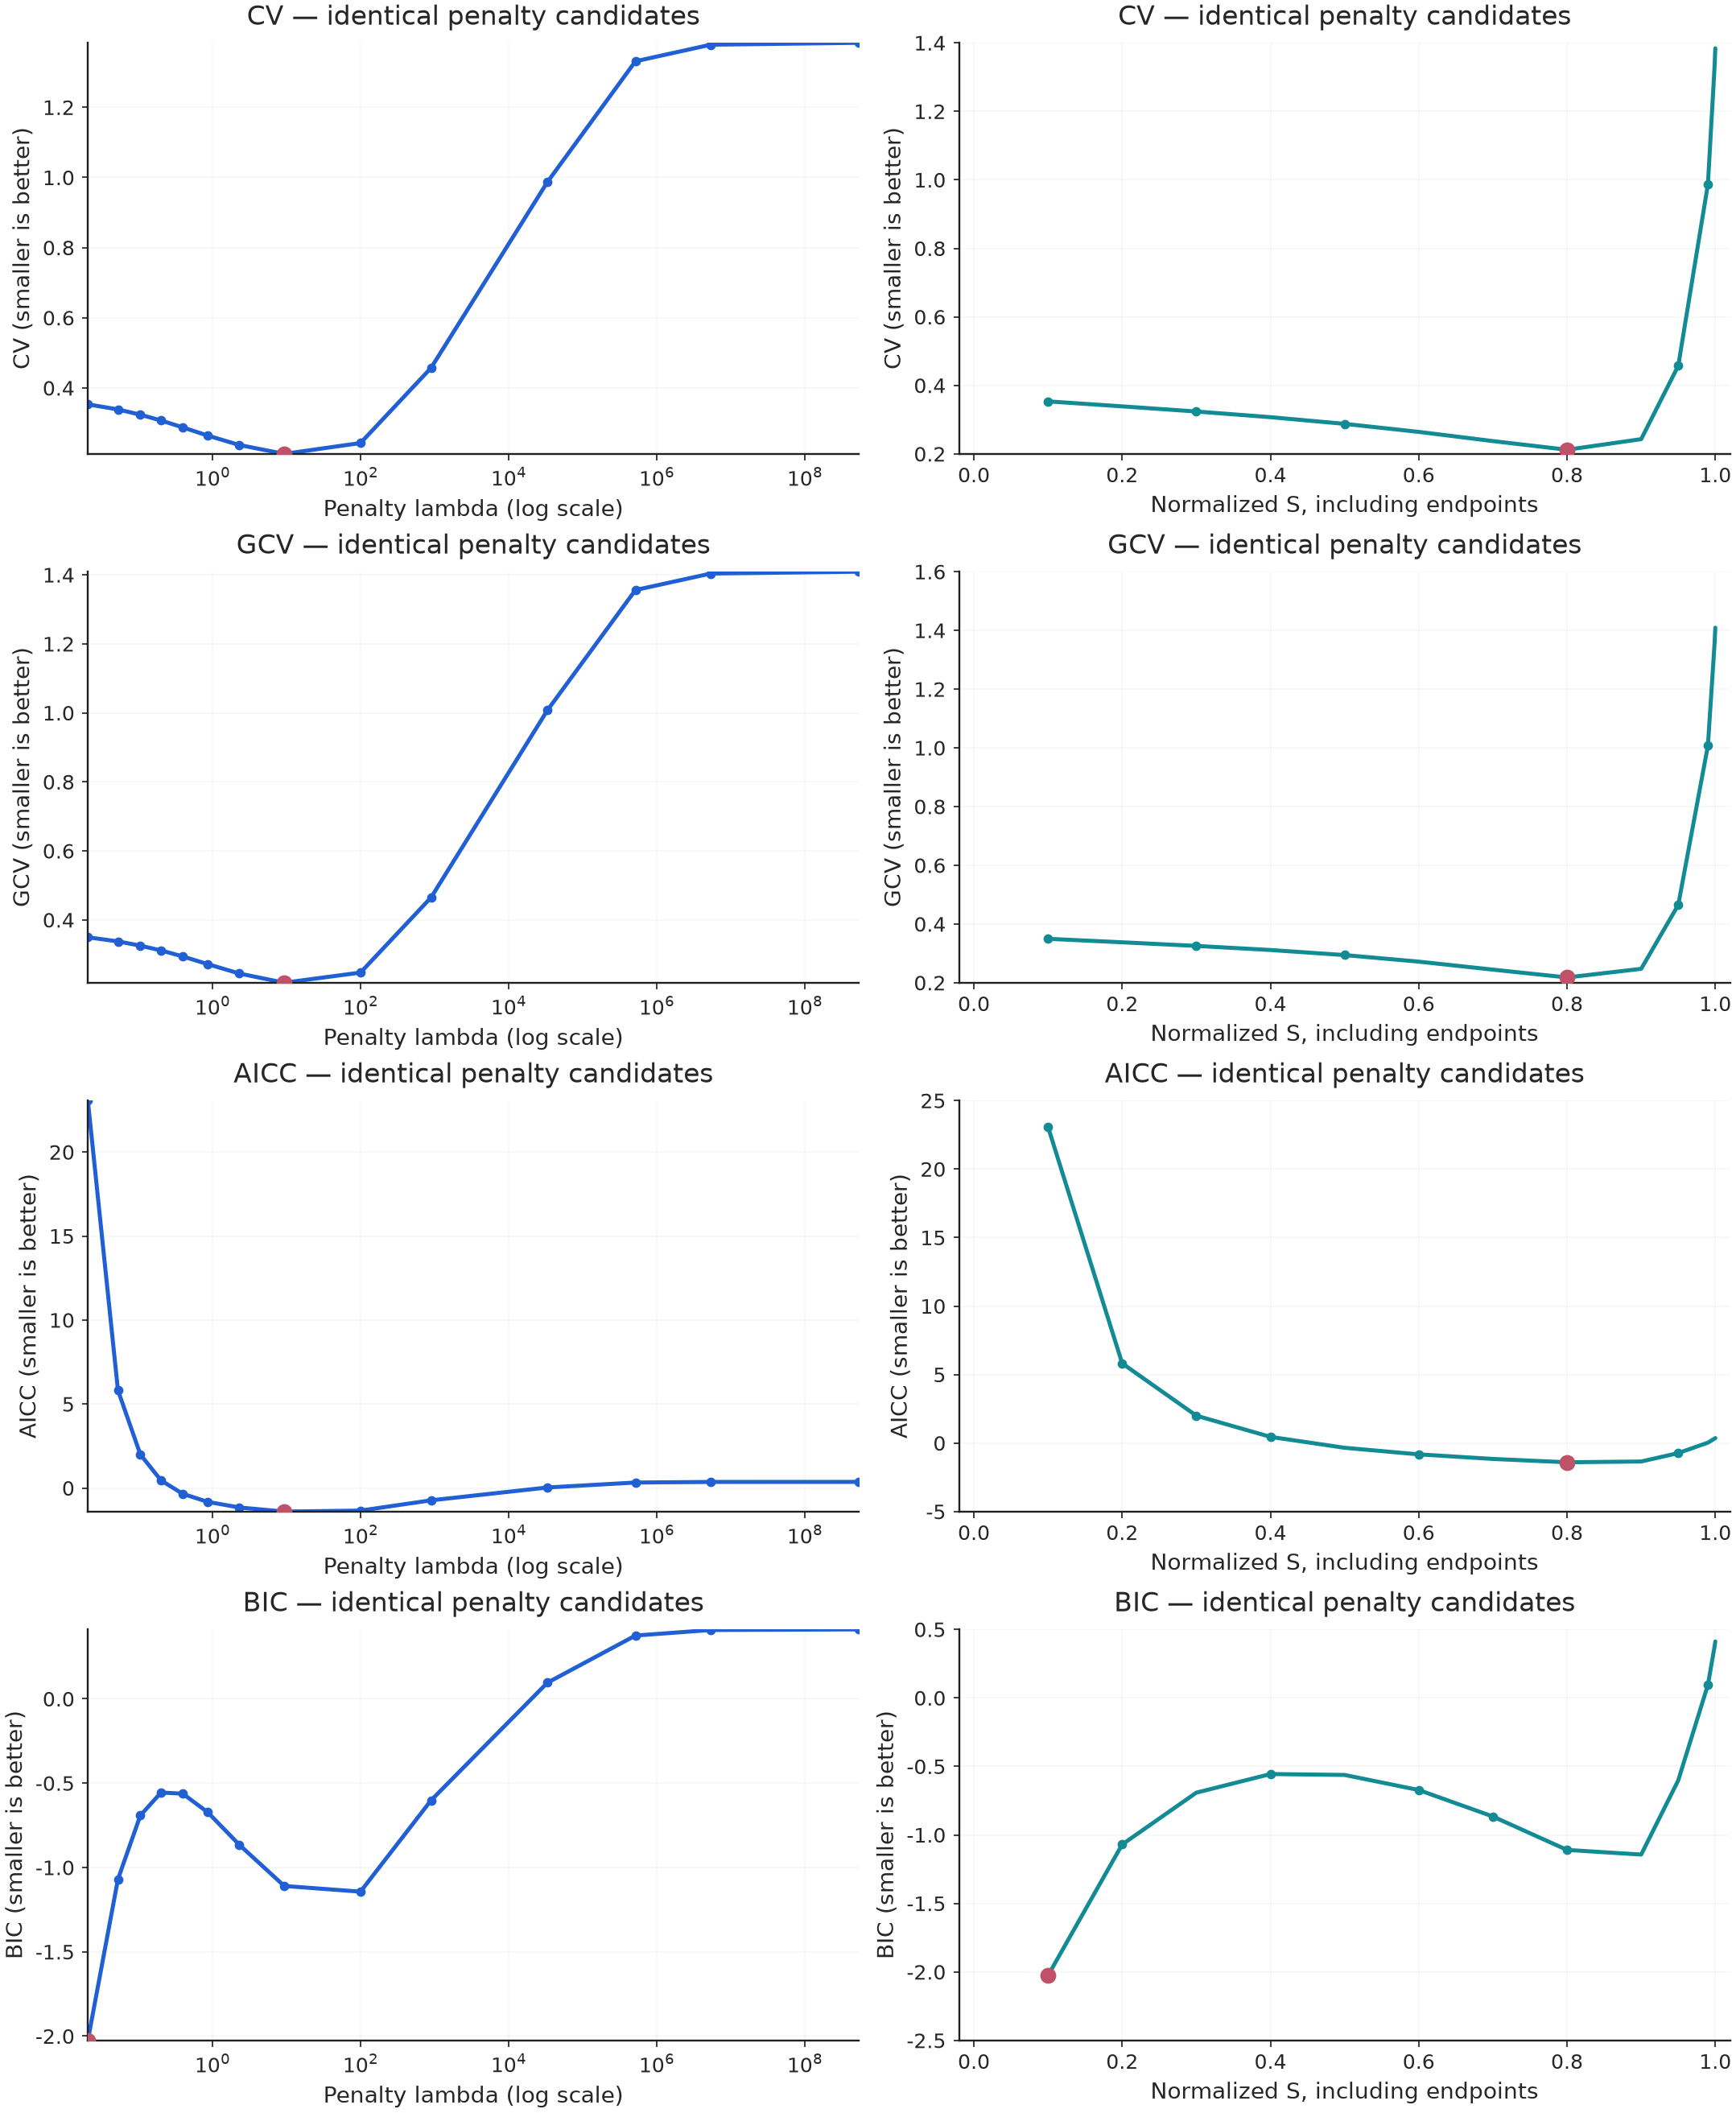

Left log-lambda plots omit 0 and infinity as coordinates, NOT as evaluated candidates. Right S plots include those endpoints. CV can be infinite at S=0 because unregularized LOOCV is undefined.


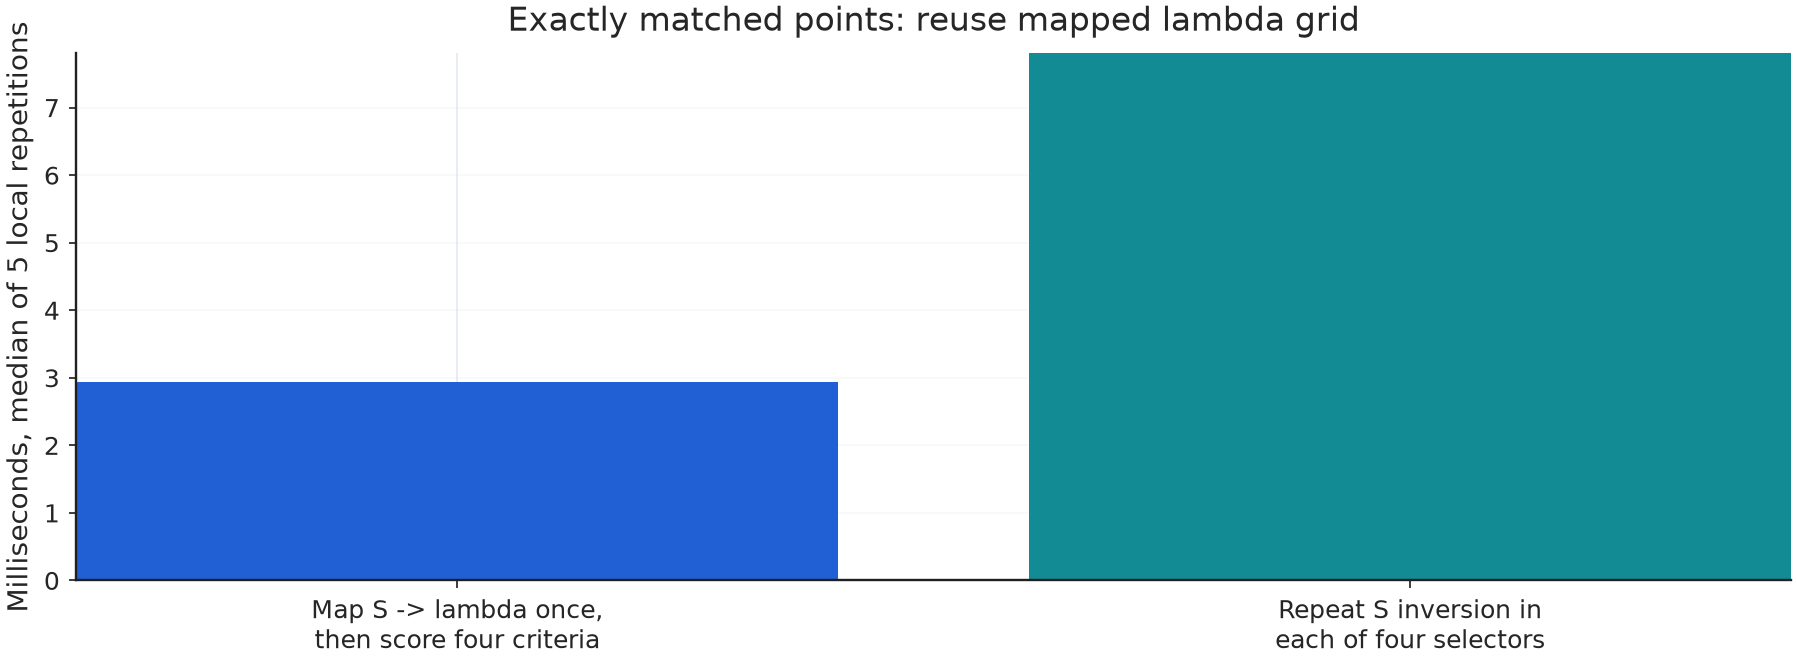

Four-criterion sweep, lambda-map-once: 2.937 ms; direct S selector (repeated mapping): 7.805 ms.
Both evaluate the same 16 penalties. This small, single-session measurement isolates a reusable-grid workflow, not the general speed of every optimization method or back end.


In [6]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
